## Dataset explorative Analysis

### Bike Dataset

The "Bike Dataset" is retrieved from [Kaggle](https://www.kaggle.com/datasets/lakshmi25npathi/bike-sharing-dataset). The authors providing the data set give the following basic information:
> This dataset contains the daily count of rental bikes between the years 2011 and 2012 in the Capital bike share system (Washington D.C., USA) with the corresponding weather and seasonal information. [...] Opposed to other transport services such as bus or subway, the duration of travel, departure and arrival position is explicitly recorded in these systems. This feature turns bike sharing system into a virtual sensor network that can be used for sensing mobility in the city. Hence, it is expected that most of important events in the city could be detected via monitoring these data.

We will work with a slightly adjusted version of the dataset that contain the variables listed below. Source and further information: https://www.kaggle.com/datasets/lakshmi25npathi/bike-sharing-dataset

| Columnn   | Description  |
| --------- | ------------ |
| `dteday` | Date |
| `season` | `1` winter, `2` spring, `3` summer, `4` fall (incorrectly stated in the [description in Kaggle](https://www.kaggle.com/datasets/lakshmi25npathi/bike-sharing-dataset/data))! |
| `yr` | Year (`0` 2011, `1` 2012) |
| `mnth` | Month ( `1` to `12`) |
| `hr` | Hour (`0` to `23`) |
| `holiday` | Weather day is holiday or not (extracted from [Web Link](http://www.freemeteo.com)) |
| `weathersit` | `1`: Clear, Few clouds, Partly cloudy, Partly cloudy<br>`2`: Mist + Cloudy, Mist + Broken clouds, Mist + Few clouds, Mist<br>`3`: Light Snow, Light Rain + Thunderstorm + Scattered clouds, Light Rain + Scattered clouds<br>`4`: Heavy Rain + Ice Pallets + Thunderstorm + Mist, Snow + Fog |
| `temp` | Temperature in Celsius (only in hourly scale) |
| `atemp` | Feeling temperature in Celsius (only in hourly scale) |
| `hum` | Humidity |
| `windspeed` | Wind speed |
| ========= | ================================================================ |
| `cnt` | Count of total rental bikes including both casual and registered |


In [35]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('../data/raw/bike_sharing/bikes.csv')
df

,dteday,season,yr,mnth,hr,holiday,weathersit,temp,atemp,hum,windspeed,cnt
0,2011-01-01,1,0,1.0,0,0,1.0,3.28,3.0014,81.0,0.0,16.0
1,2011-01-01,1,0,1.0,1,0,NaN,2.34,1.9982,80.0,0.0,40.0
2,2011-01-01,1,0,NaN,2,0,1.0,2.34,1.9982,80.0,0.0,32.0
3,2011-01-01,1,0,1.0,3,0,1.0,3.28,3.0014,75.0,0.0,13.0
4,2011-01-01,1,0,1.0,4,0,1.0,3.28,3.0014,75.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...
17374,2012-12-31,1,1,NaN,19,0,NaN,4.22,1.0016,60.0,11.0014,119.0
17375,2012-12-31,1,1,NaN,20,0,NaN,4.22,1.0016,60.0,11.0014,89.0
17376,2012-12-31,1,1,NaN,21,0,NaN,4.22,1.0016,60.0,11.0014,90.0
17377,2012-12-31,1,1,12.0,22,0,1.0,4.22,1.9982,56.0,8.9981,61.0


In [38]:
#small preprocessing

df['cnt'] = df['cnt'].astype('UInt16')
df['windspeed'] = df['windspeed'].replace('-', None).astype('float')
df[['mnth', 'weathersit']] = df[['mnth', 'weathersit']].astype('UInt8')
df['season'] = df['season'].replace({1:'winter', 2:'spring', 3:'summer', 4:'fall'})
df

,dteday,season,yr,mnth,hr,holiday,weathersit,temp,atemp,hum,windspeed,cnt
0,2011-01-01,winter,0,1,0,0,1,3.28,3.0014,81.0,0.0000,16
1,2011-01-01,winter,0,1,1,0,<NA>,2.34,1.9982,80.0,0.0000,40
2,2011-01-01,winter,0,<NA>,2,0,1,2.34,1.9982,80.0,0.0000,32
3,2011-01-01,winter,0,1,3,0,1,3.28,3.0014,75.0,0.0000,13
4,2011-01-01,winter,0,1,4,0,1,3.28,3.0014,75.0,0.0000,1
...,...,...,...,...,...,...,...,...,...,...,...,...
17374,2012-12-31,winter,1,<NA>,19,0,<NA>,4.22,1.0016,60.0,11.0014,119
17375,2012-12-31,winter,1,<NA>,20,0,<NA>,4.22,1.0016,60.0,11.0014,89
17376,2012-12-31,winter,1,<NA>,21,0,<NA>,4.22,1.0016,60.0,11.0014,90
17377,2012-12-31,winter,1,12,22,0,1,4.22,1.9982,56.0,8.9981,61


In [27]:
df.shape

(17379, 12)

In [28]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 12 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   dteday      17379 non-null  object 
 1   season      17379 non-null  object 
 2   yr          17379 non-null  int64  
 3   mnth        11824 non-null  UInt8  
 4   hr          17379 non-null  int64  
 5   holiday     17379 non-null  int64  
 6   weathersit  13209 non-null  UInt8  
 7   temp        17379 non-null  float64
 8   atemp       17379 non-null  float64
 9   hum         17379 non-null  float64
 10  windspeed   15395 non-null  float64
 11  cnt         17247 non-null  UInt16 
dtypes: UInt16(1), UInt8(2), float64(4), int64(3), object(2)
memory usage: 1.3+ MB


In [29]:
# select a subset of columns
df[['temp', 'cnt', 'weathersit']].head()


,temp,cnt,weathersit
0,3.28,16,1
1,2.34,40,<NA>
2,2.34,32,1
3,3.28,13,1
4,3.28,1,1


In [40]:
#statistical overview
df.describe()

,yr,mnth,hr,holiday,weathersit,temp,atemp,hum,windspeed,cnt
count,17379.000000,11824.0,17379.000000,17379.000000,13209.0,17379.000000,17379.000000,17379.000000,15395.000000,17247.0
mean,0.502561,6.51184,11.546752,0.028770,1.421834,15.358397,15.401157,62.722884,12.744627,189.619006
std,0.500008,3.432637,6.914405,0.167165,0.637959,9.050138,11.342114,19.292983,8.187781,181.315227
min,0.000000,1.0,0.000000,0.000000,1.0,-7.060000,-16.000000,0.000000,0.000000,1.0
25%,0.000000,4.0,6.000000,0.000000,1.0,7.980000,5.997800,48.000000,7.001500,40.0
50%,1.000000,7.0,12.000000,0.000000,1.0,15.500000,15.996800,63.000000,12.998000,142.0
75%,1.000000,9.0,18.000000,0.000000,2.0,23.020000,24.999200,78.000000,16.997900,281.0
max,1.000000,12.0,23.000000,1.000000,4.0,39.000000,50.000000,100.000000,56.996900,977.0


In [32]:
# value counts of weathersit
df['weathersit'].value_counts()

weathersit
1    8711
2    3427
3    1068
4       3
Name: count, dtype: Int64

In [ ]:
#where are missing values?

missing = df.isna().sum().sort_values(ascending=False)
missing_df = (missing.to_frame('missing_count')
              .assign(missing_pct=lambda x: 100*x['missing_count']/len(df)))
missing_df

,missing_count,missing_pct
mnth,5555,31.963864
weathersit,4170,23.994476
windspeed,1984,11.416077
cnt,132,0.759537
yr,0,0.000000
season,0,0.000000
dteday,0,0.000000
hr,0,0.000000
temp,0,0.000000
holiday,0,0.000000


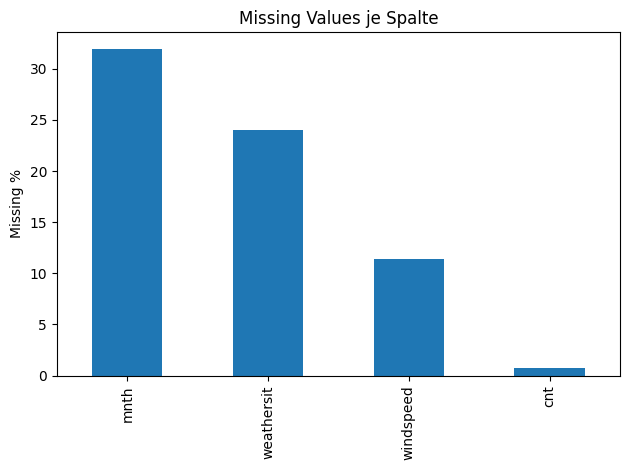

In [41]:
ax = missing_df[missing_df['missing_count']>0]['missing_pct'].plot(kind='bar')
ax.set_ylabel('Missing %')
ax.set_title('Missing Values je Spalte')
plt.tight_layout()
plt.show()

In [37]:
dup_count = df.duplicated().sum()
print('Duplikate (ganze Zeile):', dup_count)

Duplikate (ganze Zeile): 0


In [39]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 12 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   dteday      17379 non-null  object 
 1   season      17379 non-null  object 
 2   yr          17379 non-null  int64  
 3   mnth        11824 non-null  UInt8  
 4   hr          17379 non-null  int64  
 5   holiday     17379 non-null  int64  
 6   weathersit  13209 non-null  UInt8  
 7   temp        17379 non-null  float64
 8   atemp       17379 non-null  float64
 9   hum         17379 non-null  float64
 10  windspeed   15395 non-null  float64
 11  cnt         17247 non-null  UInt16 
dtypes: UInt16(1), UInt8(2), float64(4), int64(3), object(2)
memory usage: 1.3+ MB


## 4. Sanfte Bereinigung für EDA

Wir erstellen eine bereinigte Kopie `dfc` nur für Analysezwecke:
- `dteday` zu Datum
- `mnth` aus Datum rekonstruieren, falls fehlend

Wichtig: Diese Schritte sind keine endgültige Preprocessing Pipeline. Ziel ist, saubere Visualisierungen und verlässliche EDA zu ermöglichen.

In [42]:
dfc = df.copy()

# Parse date (idempotent)
dfc['dteday'] = pd.to_datetime(dfc['dteday'], errors='coerce')

# Reconstruct month where missing
if 'mnth' in dfc.columns:
    mnth_from_date = dfc['dteday'].dt.month
    
    dfc['mnth'] = (
        dfc['mnth']                
        .fillna(mnth_from_date)
    )

# Recompute missing overview
missing2 = dfc.isna().sum().sort_values(ascending=False)
missing2.head(20)


weathersit    4170
windspeed     1984
cnt            132
dteday           0
mnth             0
yr               0
season           0
hr               0
temp             0
holiday          0
hum              0
atemp            0
dtype: int64

In [43]:
dfc.head(10)

,dteday,season,yr,mnth,hr,holiday,weathersit,temp,atemp,hum,windspeed,cnt
0,2011-01-01,winter,0,1,0,0,1,3.28,3.0014,81.0,0.0000,16
1,2011-01-01,winter,0,1,1,0,<NA>,2.34,1.9982,80.0,0.0000,40
2,2011-01-01,winter,0,1,2,0,1,2.34,1.9982,80.0,0.0000,32
3,2011-01-01,winter,0,1,3,0,1,3.28,3.0014,75.0,0.0000,13
4,2011-01-01,winter,0,1,4,0,1,3.28,3.0014,75.0,0.0000,1
5,2011-01-01,winter,0,1,5,0,2,3.28,1.0016,75.0,6.0032,1
6,2011-01-01,winter,0,1,6,0,1,2.34,1.9982,80.0,0.0000,2
7,2011-01-01,winter,0,1,7,0,1,1.40,1.0016,86.0,0.0000,3
8,2011-01-01,winter,0,1,8,0,1,3.28,3.0014,75.0,0.0000,8
9,2011-01-01,winter,0,1,9,0,1,7.04,7.0010,76.0,0.0000,14


## 5. Univariate Analyse

### 5.1 Zielvariable `cnt`
Verteilung, Log-Skala, Ausreißer.

In [44]:
target = 'cnt'
print(dfc[target].describe())

count       17247.0
mean     189.619006
std      181.315227
min             1.0
25%            40.0
50%           142.0
75%           281.0
max           977.0
Name: cnt, dtype: Float64


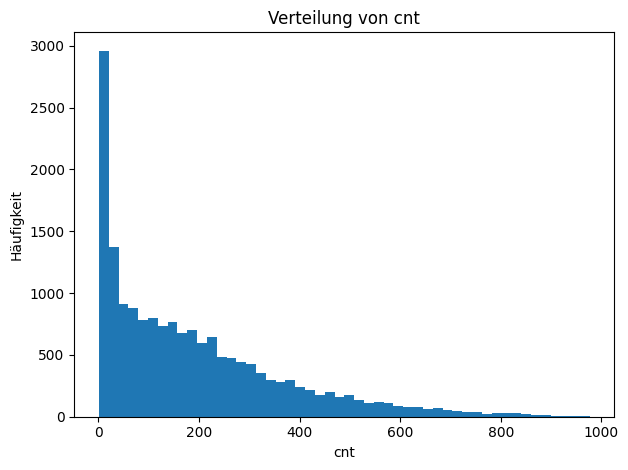

In [48]:
fig, ax = plt.subplots()
ax.hist(dfc[target].dropna(), bins=50)
ax.set_title('Verteilung von cnt')
ax.set_xlabel('cnt')
ax.set_ylabel('Häufigkeit')
plt.tight_layout()
plt.show()

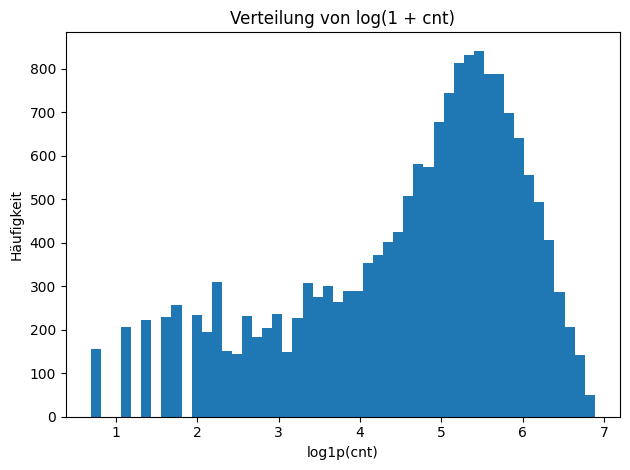

In [49]:
fig, ax = plt.subplots()
ax.hist(np.log1p(dfc[target].dropna()), bins=50)
ax.set_title('Verteilung von log(1 + cnt)')
ax.set_xlabel('log1p(cnt)')
ax.set_ylabel('Häufigkeit')
plt.tight_layout()
plt.show()

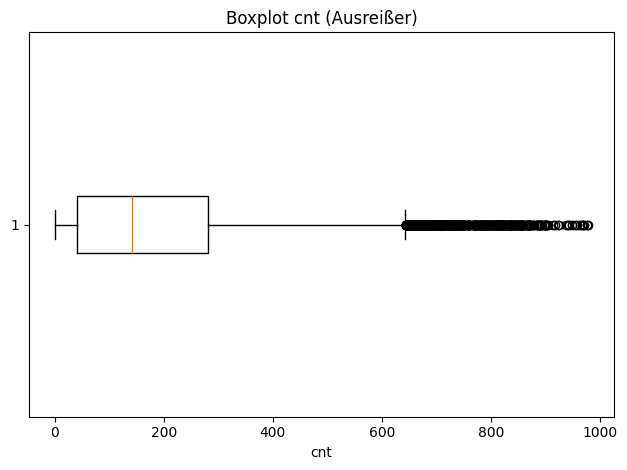

In [50]:
fig, ax = plt.subplots()
ax.boxplot(dfc[target].dropna(), vert=False)
ax.set_title('Boxplot cnt (Ausreißer)')
ax.set_xlabel('cnt')
plt.tight_layout()
plt.show()

### 5.2 Numerische Features

In [51]:
num_cols = dfc.select_dtypes(include=[np.number]).columns.tolist()
num_cols

['yr',
 'mnth',
 'hr',
 'holiday',
 'weathersit',
 'temp',
 'atemp',
 'hum',
 'windspeed',
 'cnt']

In [52]:
dfc[num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
yr,17379.0,0.502561,0.500008,0.0,0.0,1.0,1.0,1.0
mnth,17379.0,6.537775,3.438776,1.0,4.0,7.0,10.0,12.0
hr,17379.0,11.546752,6.914405,0.0,6.0,12.0,18.0,23.0
holiday,17379.0,0.02877,0.167165,0.0,0.0,0.0,0.0,1.0
weathersit,13209.0,1.421834,0.637959,1.0,1.0,1.0,2.0,4.0
temp,17379.0,15.358397,9.050138,-7.06,7.98,15.5,23.02,39.0
atemp,17379.0,15.401157,11.342114,-16.0,5.9978,15.9968,24.9992,50.0
hum,17379.0,62.722884,19.292983,0.0,48.0,63.0,78.0,100.0
windspeed,15395.0,12.744627,8.187781,0.0,7.0015,12.998,16.9979,56.9969
cnt,17247.0,189.619006,181.315227,1.0,40.0,142.0,281.0,977.0


## 6. Zeitliche Muster

Wir betrachten Tagesverläufe, Wochenmuster und Saisonalität.

In [53]:
dfc['hr'] = pd.to_numeric(dfc['hr'], errors='coerce')

if 'dteday' in dfc.columns and 'hr' in dfc.columns:
    dfc['datetime'] = dfc['dteday'] + pd.to_timedelta(dfc['hr'].fillna(0).astype(int), unit='h')

# Zusätzliche Zeitfeatures
if 'dteday' in dfc.columns:
    dfc['dow'] = dfc['dteday'].dt.dayofweek  # 0=Montag
    dfc['month'] = dfc['dteday'].dt.month
    dfc['day'] = dfc['dteday'].dt.day

dfc[['dteday', 'hr', 'datetime', 'dow', 'month']].head()

,dteday,hr,datetime,dow,month
0,2011-01-01,0,2011-01-01 00:00:00,5,1
1,2011-01-01,1,2011-01-01 01:00:00,5,1
2,2011-01-01,2,2011-01-01 02:00:00,5,1
3,2011-01-01,3,2011-01-01 03:00:00,5,1
4,2011-01-01,4,2011-01-01 04:00:00,5,1


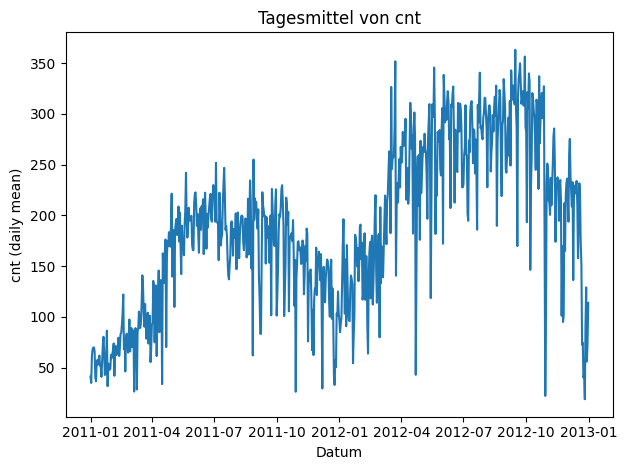

In [54]:
if 'datetime' in dfc.columns:
    ts = dfc.sort_values('datetime').set_index('datetime')[target]
    # Tagesmittel
    daily = ts.resample('D').mean()

    fig, ax = plt.subplots()
    ax.plot(daily.index, daily.values)
    ax.set_title('Tagesmittel von cnt')
    ax.set_xlabel('Datum')
    ax.set_ylabel('cnt (daily mean)')
    plt.tight_layout()
    plt.show()
else:
    print('datetime nicht verfügbar')

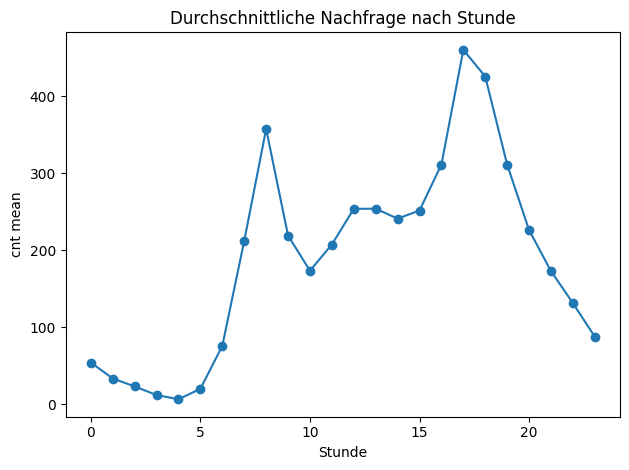

In [55]:
if 'hr' in dfc.columns:
    hourly_mean = dfc.groupby('hr')[target].mean()
    fig, ax = plt.subplots()
    ax.plot(hourly_mean.index, hourly_mean.values, marker='o')
    ax.set_title('Durchschnittliche Nachfrage nach Stunde')
    ax.set_xlabel('Stunde')
    ax.set_ylabel('cnt mean')
    plt.tight_layout()
    plt.show()

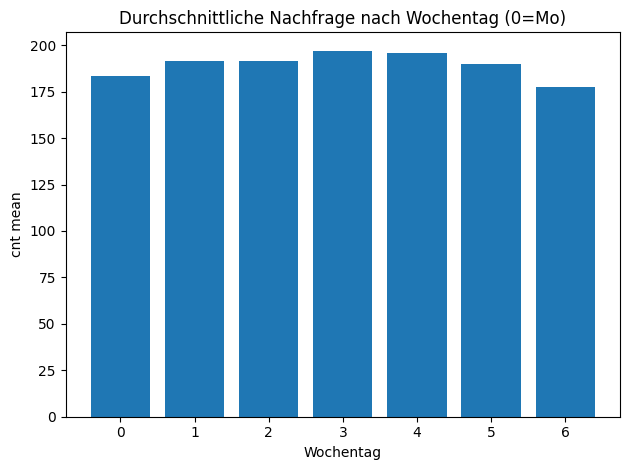

In [56]:
if 'dow' in dfc.columns:
    dow_mean = dfc.groupby('dow')[target].mean()
    fig, ax = plt.subplots()
    ax.bar(dow_mean.index.astype(int), dow_mean.values)
    ax.set_title('Durchschnittliche Nachfrage nach Wochentag (0=Mo)')
    ax.set_xlabel('Wochentag')
    ax.set_ylabel('cnt mean')
    plt.tight_layout()
    plt.show()

## 7. Kategorien und Zielvariable

Wir prüfen, wie sich `cnt` nach Saison, Feiertag und Wetterlage unterscheidet.

In [57]:
cat_cols = []
for c in ['season', 'holiday', 'weathersit', 'yr', 'mnth']:
    if c in dfc.columns:
        cat_cols.append(c)
cat_cols

['season', 'holiday', 'weathersit', 'yr', 'mnth']

In [58]:
for c in cat_cols:
    tmp = dfc.groupby(c)[target].agg(['count','mean','median'])
    print('\n', c)
    display(tmp)


 season


,count,mean,median
season,,,
fall,4201,198.872887,156.0
spring,4372,208.685956,165.0
summer,4471,235.999105,200.0
winter,4203,111.19843,76.0



 holiday


,count,mean,median
holiday,,,
0,16751,190.60671,144.0
1,496,156.262097,97.0



 weathersit


,count,mean,median
weathersit,,,
1,8653,203.859702,158.0
2,3396,175.812721,134.0
3,1057,109.654683,63.0
4,3,74.333333,36.0



 yr


,count,mean,median
yr,,,
0,8577,144.032762,110.0
1,8670,234.716263,191.0



 mnth


,count,mean,median
mnth,,,
1,1418,94.898449,66.5
2,1328,112.839608,82.0
3,1460,155.071233,103.0
4,1421,188.009148,137.0
5,1481,222.503714,188.0
6,1430,241.06014,204.0
7,1483,231.542144,202.0
8,1462,238.585499,205.0
9,1426,241.326788,190.0


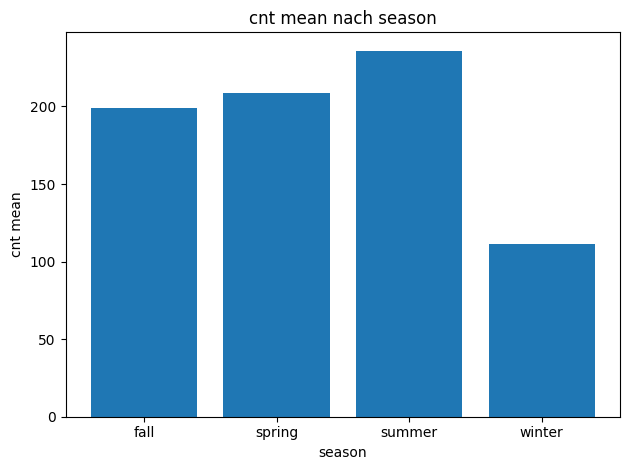

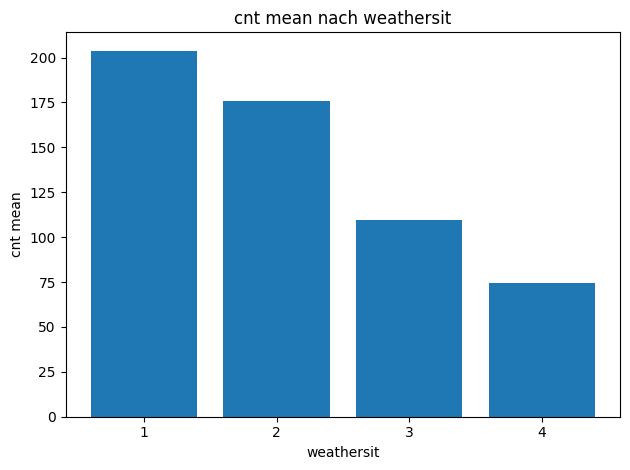

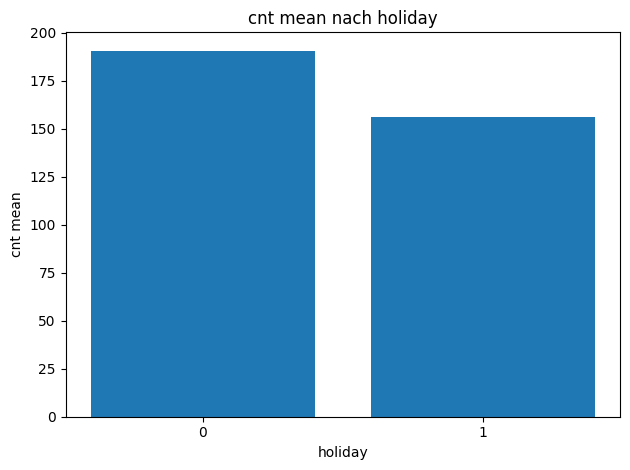

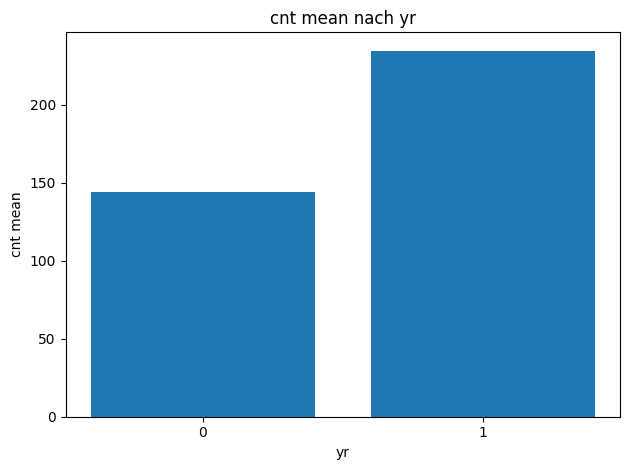

In [59]:
for c in ['season','weathersit','holiday','yr']:
    if c in dfc.columns:
        grp = dfc.groupby(c)[target].mean().sort_index()
        fig, ax = plt.subplots()
        ax.bar(grp.index.astype(str), grp.values)
        ax.set_title(f'cnt mean nach {c}')
        ax.set_xlabel(c)
        ax.set_ylabel('cnt mean')
        plt.tight_layout()
        plt.show()

C:\Users\hummi\AppData\Local\Temp\ipykernel_26200\2873686976.py:8: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=[str(g) for g in groups], showfliers=False)


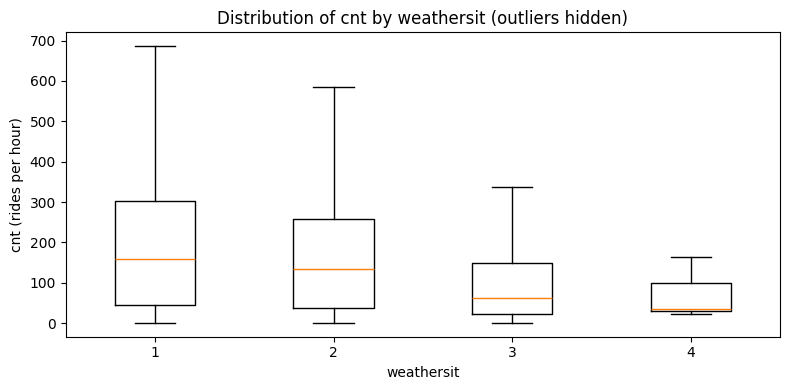

In [60]:
# Boxplot: cnt nach weathersit
dfp = dfc.copy()

groups = [1, 2, 3, 4]
data = [dfp.loc[dfp['weathersit'] == g, 'cnt'].dropna().values for g in groups]

plt.figure(figsize=(8, 4))
plt.boxplot(data, labels=[str(g) for g in groups], showfliers=False)
plt.xlabel('weathersit')
plt.ylabel('cnt (rides per hour)')
plt.title('Distribution of cnt by weathersit (outliers hidden)')
plt.tight_layout()
plt.show()


C:\Users\hummi\AppData\Local\Temp\ipykernel_26200\1955402232.py:13: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=[str(g) for g in groups], showfliers=False)


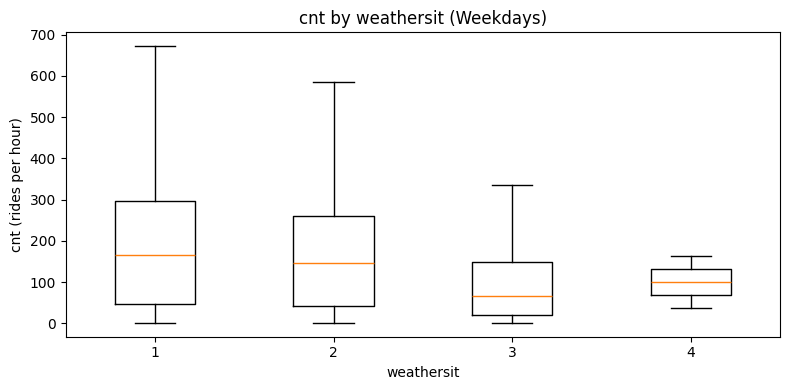

C:\Users\hummi\AppData\Local\Temp\ipykernel_26200\1955402232.py:13: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=[str(g) for g in groups], showfliers=False)


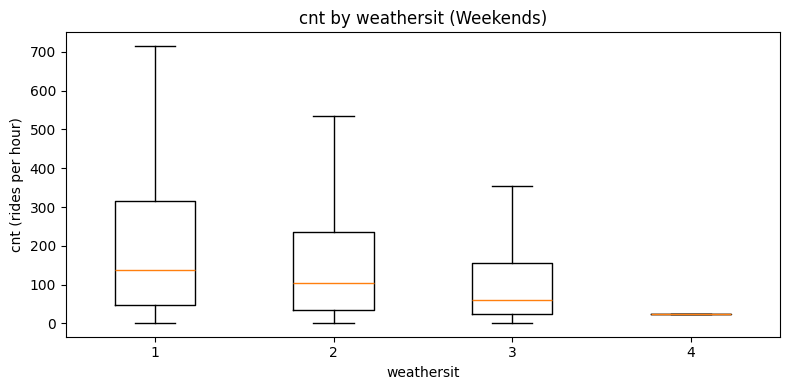

C:\Users\hummi\AppData\Local\Temp\ipykernel_26200\1955402232.py:13: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=[str(g) for g in groups], showfliers=False)


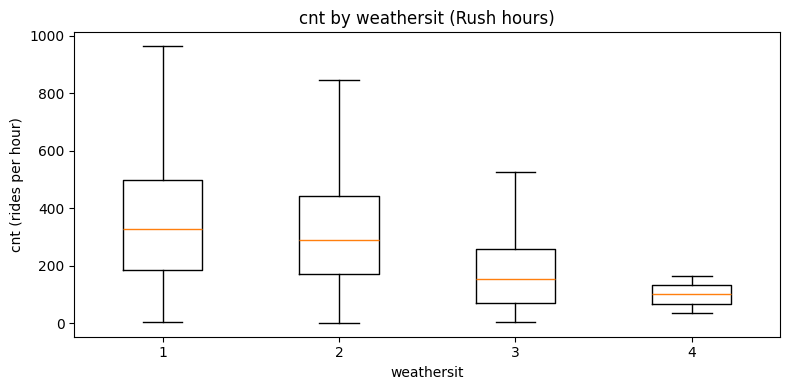

C:\Users\hummi\AppData\Local\Temp\ipykernel_26200\1955402232.py:13: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=[str(g) for g in groups], showfliers=False)


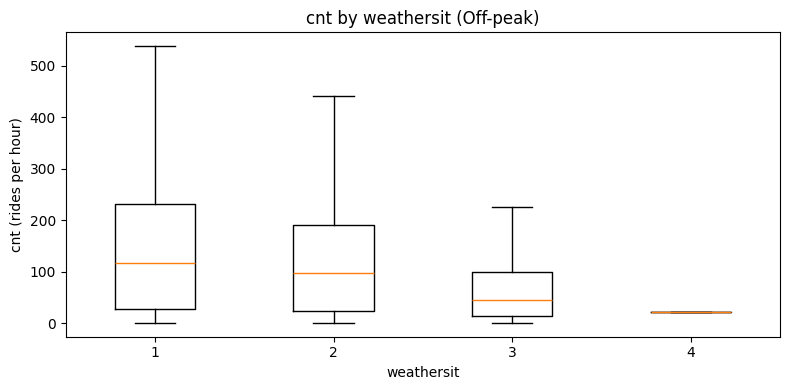

In [61]:
# Splits: weekday vs weekend + rush vs off-peak
dfp2 = dfc.copy()

dfp2['dow'] = dfp2['dteday'].dt.dayofweek          # 0=Mon ... 6=Sun
dfp2['is_weekend'] = dfp2['dow'].isin([5, 6])

dfp2['is_rush'] = dfp2['hr'].isin([7, 8, 9, 16, 17, 18])

def boxplot_by_subset(dfx, title):
    groups = [1, 2, 3, 4]
    data = [dfx.loc[dfx['weathersit'] == g, 'cnt'].dropna().values for g in groups]
    plt.figure(figsize=(8, 4))
    plt.boxplot(data, labels=[str(g) for g in groups], showfliers=False)
    plt.xlabel('weathersit')
    plt.ylabel('cnt (rides per hour)')
    plt.title(title)
    plt.tight_layout()
    plt.show()

boxplot_by_subset(dfp2[~dfp2['is_weekend']], 'cnt by weathersit (Weekdays)')
boxplot_by_subset(dfp2[dfp2['is_weekend']], 'cnt by weathersit (Weekends)')

boxplot_by_subset(dfp2[dfp2['is_rush']], 'cnt by weathersit (Rush hours)')
boxplot_by_subset(dfp2[~dfp2['is_rush']], 'cnt by weathersit (Off-peak)')


## 8. Beziehungen zwischen numerischen Variablen

Korrelationen, Scatterplots, ggf. Heatmap.

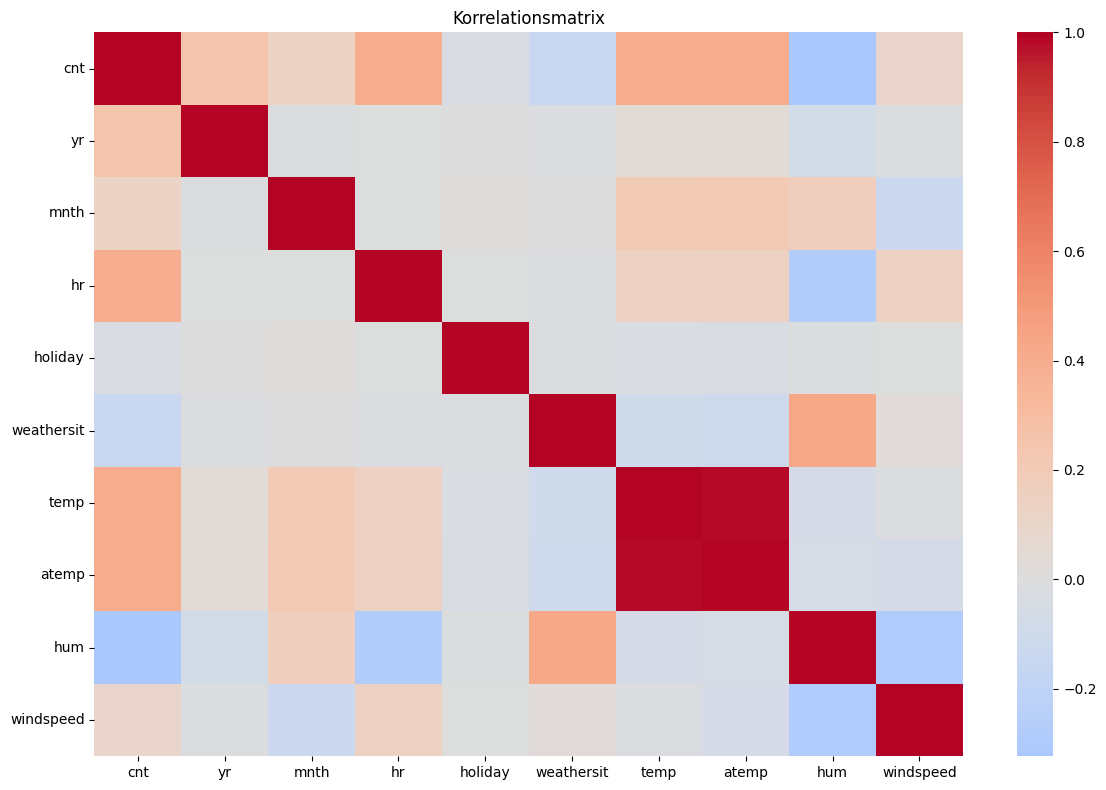

In [65]:
import seaborn as sns

num_for_corr = [c for c in num_cols if c != target]

corr = dfc[[target] + num_for_corr].corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(12, 8))
sns.heatmap(corr, ax=ax, annot=False, cmap='coolwarm', center=0)
ax.set_title('Korrelationsmatrix')
plt.tight_layout()
plt.show()


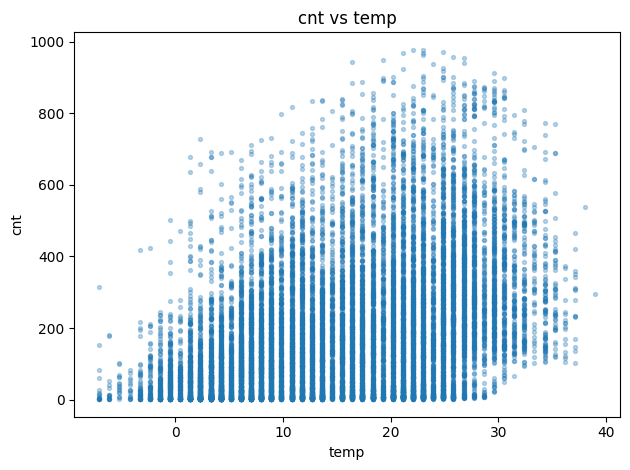

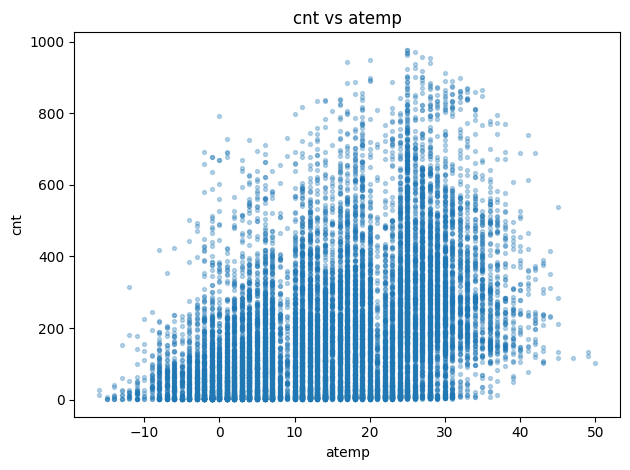

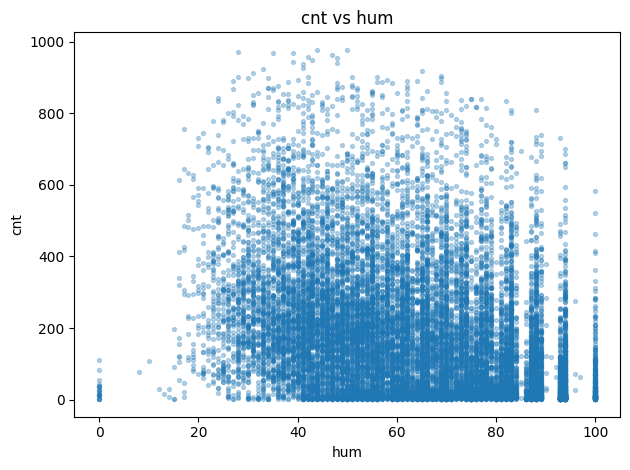

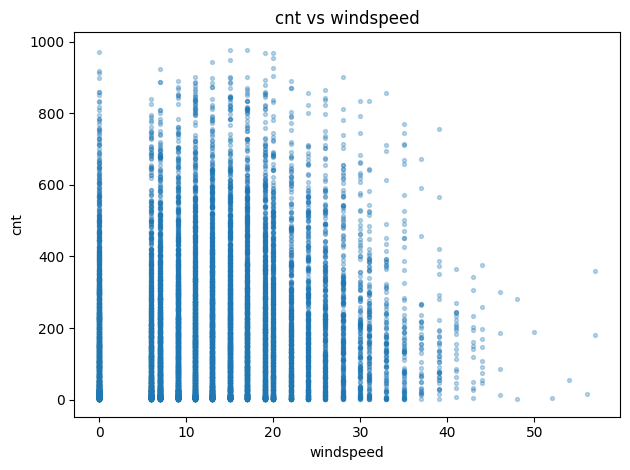

In [66]:
scatter_pairs = [('temp', target), ('atemp', target), ('hum', target), ('windspeed', target)]
for x, y in scatter_pairs:
    if x in dfc.columns:
        fig, ax = plt.subplots()
        ax.scatter(dfc[x], dfc[y], s=8, alpha=0.3)
        ax.set_title(f'{y} vs {x}')
        ax.set_xlabel(x)
        ax.set_ylabel(y)
        plt.tight_layout()
        plt.show()

## 9. Data Quality Deep Dive

### 9.1 Missingness Muster

Wir prüfen, ob Missing Values systematisch mit Zeit oder anderen Spalten zusammenhängen.

In [67]:
missing_cols = missing_df.index[missing_df['missing_count']>0].tolist()
missing_cols

['mnth', 'weathersit', 'windspeed', 'cnt']

,missing_rate
miss_weathersit,0.239945
miss_windspeed,0.114161
miss_cnt,0.007595
miss_mnth,0.000000


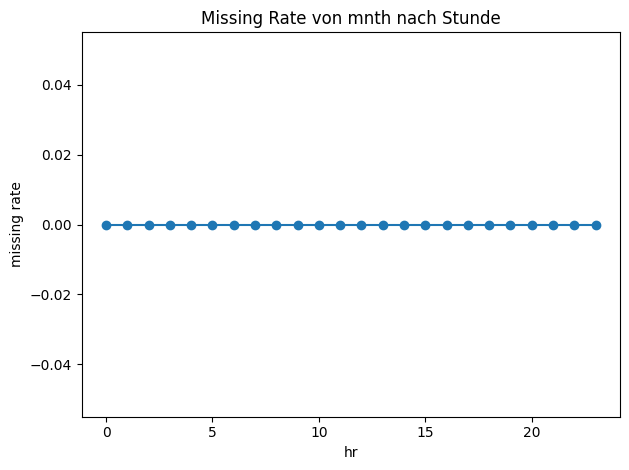

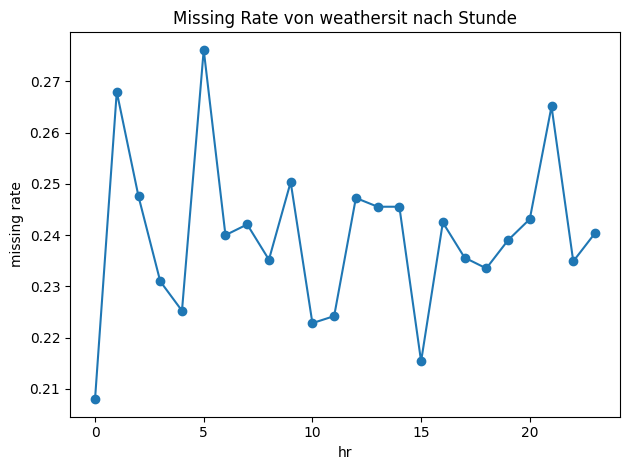

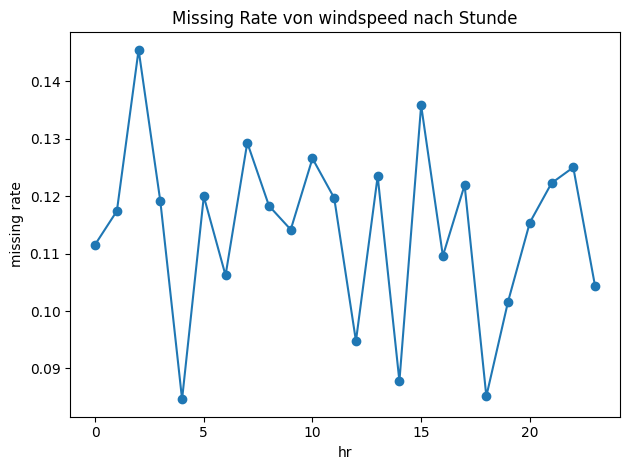

In [68]:
if missing_cols:
    miss_ind = dfc[missing_cols].isna().astype(int)
    miss_ind.columns = [f'miss_{c}' for c in missing_cols]
    miss_summary = miss_ind.mean().sort_values(ascending=False)
    display(miss_summary.to_frame('missing_rate'))

    # Missingness über Stunde
    if 'hr' in dfc.columns:
        for c in missing_cols[:3]:
            fig, ax = plt.subplots()
            rate = dfc.groupby('hr')[c].apply(lambda s: s.isna().mean())
            ax.plot(rate.index, rate.values, marker='o')
            ax.set_title(f'Missing Rate von {c} nach Stunde')
            ax.set_xlabel('hr')
            ax.set_ylabel('missing rate')
            plt.tight_layout()
            plt.show()
else:
    print('Keine Missing Columns')

### 9.2 Plausibilitätschecks

Beispiele:
- `temp` und `atemp` sollten positiv korrelieren
- `hum` liegt oft zwischen 0 und 100
- `windspeed` sollte nicht negativ sein

In [69]:
checks = {
    'temp_range': (dfc['temp'].min(), dfc['temp'].max()) if 'temp' in dfc.columns else None,
    'atemp_range': (dfc['atemp'].min(), dfc['atemp'].max()) if 'atemp' in dfc.columns else None,
    'hum_range': (dfc['hum'].min(), dfc['hum'].max()) if 'hum' in dfc.columns else None,
    'windspeed_range': (dfc['windspeed'].min(), dfc['windspeed'].max()) if 'windspeed' in dfc.columns else None,
}
checks

{'temp_range': (np.float64(-7.06), np.float64(39.0)),
 'atemp_range': (np.float64(-16.0), np.float64(50.0)),
 'hum_range': (np.float64(0.0), np.float64(100.0)),
 'windspeed_range': (np.float64(0.0), np.float64(56.996900000000004))}

## Zusammenfassung der explorativen Datenanalyse (EDA)

### 1. Datengrundlage und Qualität
Der Datensatz umfasst stündliche Bike Sharing Beobachtungen über zwei Jahre mit insgesamt ca. 17.000 Zeilen.  
Die meisten Features sind vollständig, jedoch treten Missing Values insbesondere bei folgenden Variablen auf:
- `mnth`
- `weathersit`
- `windspeed`
- `cnt`

Ein Teil dieser Missing Values konnte sinnvoll imputiert werden, insbesondere `mnth` auf Basis von `dteday`.  
Andere fehlende Werte (z. B. Wetterinformationen) wurden bewusst beibehalten, da sie nicht eindeutig rekonstruierbar sind.

---

### 2. Zeitliche Struktur
- Die Daten sind stündlich aufgelöst.
- Aus `dteday` und `hr` wurde ein konsistenter Zeitstempel (`datetime`) erzeugt.
- Der berechnete Wochentag (`dow`) ist korrekt interpretiert (0 = Montag, 6 = Sonntag).
- Der 01.01.2011 fällt korrekt auf einen Samstag, was die zeitliche Konsistenz bestätigt.

Es zeigen sich klare zeitliche Muster:
- Deutliche Nachfragepeaks zu typischen Pendlerzeiten.
- Unterschiede zwischen Wochenenden und Werktagen.
- Starke saisonale Effekte über Monate und Jahreszeiten hinweg.

---

### 3. Zielvariable `cnt`
Die Zielvariable (Anzahl Ausleihen pro Stunde) weist:
- eine stark rechtsschiefe Verteilung
- viele niedrige Werte
- wenige, sehr hohe Spitzenwerte

auf.  
Der Mittelwert liegt systematisch über dem Median, was auf das Vorhandensein von Nachfrage-Spitzen hinweist.

---

### 4. Kategorielle Features

#### Wetter (`weathersit`)
- Es besteht ein klar negativer Zusammenhang zwischen Wetterverschlechterung und Nachfrage.
- Gute Wetterbedingungen dominieren den Datensatz.
- Sehr schlechtes Wetter (Kategorie 4) kommt extrem selten vor und ist statistisch kaum belastbar.

Median und Mittelwert fallen mit zunehmender Wetterverschlechterung deutlich ab, was auf einen strukturellen Effekt und nicht nur auf Ausreißer hindeutet.

#### Weitere kategoriale Merkmale
- Feiertage, Wochentage und Jahreszeiten zeigen keinen linearen, aber einen klar diskreten Einfluss auf die Nachfrage.
- Diese Effekte sind in aggregierten Statistiken und Verteilungen deutlich sichtbar, obwohl sie in linearen Korrelationen schwach erscheinen.

---

### 5. Numerische Features und Korrelationen
Die Korrelationsmatrix zeigt:
- starke positive Korrelation zwischen `cnt` und Temperatur (`temp`, `atemp`)
- sehr hohe Redundanz zwischen `temp` und `atemp`
- schwache negative Korrelationen mit `hum` und `windspeed`
- geringe lineare Korrelationen für zeitliche Features wie `hr` oder `mnth`

Wichtig:  
Geringe Pearson-Korrelation bedeutet hier nicht geringe Relevanz, sondern deutet auf **nichtlineare oder zyklische Effekte** hin.

---

### 6. Zentrale Erkenntnisse
- Nachfrage wird stark durch Zeit, Wetter und Tagesstruktur beeinflusst.
- Viele relevante Effekte sind nicht linear und werden durch einfache Korrelationen unterschätzt.
- Medianwerte sind für Interpretation oft robuster als Mittelwerte.
- Einige Features (z. B. `temp` und `atemp`) enthalten redundante Information.

---

### 7. Implikationen für weitere Schritte
- Feature Engineering (z. B. Rush Hour Flags, Wochenendindikatoren) ist entscheidend.
- Lineare Modelle benötigen sorgfältige Feature Auswahl.
- Nichtlineare Modelle (z. B. Tree-basierte Ansätze) sind gut geeignet.
- Seltene Kategorien sollten ggf. zusammengefasst oder gesondert behandelt werden.

Diese EDA liefert eine konsistente und belastbare Grundlage für Preprocessing, Feature Engineering und Modellierung.
